In [1]:
import numpy as np
import pandas as pa
import matplotlib.pyplot as plt
from keras.models import Sequential , load_model
from keras.layers import Dense , Dropout , Normalization
from keras.callbacks import EarlyStopping 
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_absolute_error , mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler , MinMaxScaler , RobustScaler , PowerTransformer
import tensorflow as tf
import keras as ks
%matplotlib widget

In [2]:
file = pa.read_csv('digikala-products.csv')
file.head()

C:\Users\A\AppData\Local\Temp\ipykernel_15468\694981599.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  file = pa.read_csv('digikala-products.csv')


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,False,0,beauty
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,False,0,beauty


In [3]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1283496 entries, 0 to 1283495
Data columns (total 12 columns):
 #   Column                Non-Null Count    Dtype 
---  ------                --------------    ----- 
 0   id                    1283496 non-null  int64 
 1   title_fa              1283496 non-null  object
 2   Rate                  1283496 non-null  int64 
 3   Rate_cnt              1283496 non-null  int64 
 4   Category1             1283496 non-null  object
 5   Category2             1073388 non-null  object
 6   Brand                 1283496 non-null  object
 7   Price                 1283496 non-null  int64 
 8   Seller                1283273 non-null  object
 9   Is_Fake               1283496 non-null  bool  
 10  min_price_last_month  1283496 non-null  int64 
 11  sub_category          1283496 non-null  object
dtypes: bool(1), int64(5), object(6)
memory usage: 108.9+ MB


In [4]:
file.describe()

,id,Rate,Rate_cnt,Price,min_price_last_month
count,1.283496e+06,1.283496e+06,1.283496e+06,1.283496e+06,1.283496e+06
mean,7.948842e+06,3.013031e+01,2.073829e+01,8.491273e+06,4.212147e+05
std,3.511631e+06,3.991098e+01,2.182101e+02,4.663222e+07,1.202546e+07
min,7.602000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.212286e+06,0.000000e+00,0.000000e+00,7.000000e+05,0.000000e+00
50%,8.715048e+06,0.000000e+00,0.000000e+00,1.560000e+06,0.000000e+00
75%,1.100891e+07,8.000000e+01,2.000000e+00,4.450000e+06,0.000000e+00
max,1.277376e+07,1.000000e+02,3.043800e+04,8.499990e+09,7.645500e+09


In [5]:
file['Price'].describe()

count    1.283496e+06
mean     8.491273e+06
std      4.663222e+07
min      0.000000e+00
25%      7.000000e+05
50%      1.560000e+06
75%      4.450000e+06
max      8.499990e+09
Name: Price, dtype: float64

In [6]:
file['sub_category'].value_counts()

sub_category
clothe                     587946
book & stationary & art    343597
beauty                     168648
toys and kids              118635
rural goods                 40893
travel                      23777
Name: count, dtype: int64

In [7]:
Q1 = file['Price'].quantile(0.25)
Q3 = file['Price'].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR

file.loc[(file['Price'] > upper) | (file['Price'] < lower),'Price']

99         10700000
558        12927000
559        12880000
560        13700000
561        14852000
             ...   
1274406    13870500
1274407    12400000
1274408    13274000
1283477    12500000
1283478    12500000
Name: Price, Length: 169044, dtype: int64

In [8]:
file['Is_Fake'].value_counts()

Is_Fake
False    1206033
True       77463
Name: count, dtype: int64

In [9]:
file.loc[(file['Price'] == 0) | (file['Price'].isna()) , 'Price'] = file['Price'].median()
file.loc[(file['Price'] > upper) | (file['Price'] < lower),'Price'] = file['Price'].median()

In [10]:
file = pa.get_dummies(file,columns=['Is_Fake'],dtype=float)
file = pa.get_dummies(file,columns=['sub_category'],dtype=float) 

In [11]:
mean_price = file.groupby('title_fa')['Price'].mean()
file['x_title_fa'] = file['title_fa'].map(mean_price)
mean_price2 = file.groupby('Brand')['Price'].mean()
file['x_Brand'] = file['Brand'].map(mean_price2)

In [12]:
file.head()

,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,min_price_last_month,Is_Fake_False,Is_Fake_True,sub_category_beauty,sub_category_book & stationary & art,sub_category_clothe,sub_category_rural goods,sub_category_toys and kids,sub_category_travel,x_title_fa,x_Brand
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,634800.0,1.992023e+06
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,818800.0,1.992023e+06
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,920000.0,1.992023e+06
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1100000.0,1.992023e+06
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1530000.0,1.525500e+06


In [13]:
X = file.drop(['id','title_fa','Brand','Rate','Rate_cnt','Category1','Category2','Seller','min_price_last_month','Price'],axis=1)
Y = file['Price']

In [14]:
X

,Is_Fake_False,Is_Fake_True,sub_category_beauty,sub_category_book & stationary & art,sub_category_clothe,sub_category_rural goods,sub_category_toys and kids,sub_category_travel,x_title_fa,x_Brand
0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,634800.0,1.992023e+06
1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,818800.0,1.992023e+06
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,920000.0,1.992023e+06
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1100000.0,1.992023e+06
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1530000.0,1.525500e+06
...,...,...,...,...,...,...,...,...,...,...
1283491,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2500000.0,1.992023e+06
1283492,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2150000.0,1.992023e+06
1283493,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2100000.0,1.992023e+06
1283494,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2300000.0,1.992023e+06


In [15]:
X_train , X_test , Y_train , Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

scaler_power_x = [
    'x_title_fa',
    'x_Brand'
]

scaler_standard_x = [
    'Is_Fake_False',
    'Is_Fake_True',
    'sub_category_beauty',
    'sub_category_book & stationary & art',
    'sub_category_clothe',
    'sub_category_rural goods',
    'sub_category_toys and kids',
    'sub_category_travel'
]

standard_scaler = StandardScaler()
standard_power = PowerTransformer()
standard_minmax = MinMaxScaler()
standard_robust = RobustScaler()
standard_power_y = PowerTransformer()

X_train[scaler_power_x] = standard_power.fit_transform(X_train[scaler_power_x])
X_test[scaler_power_x] = standard_power.transform(X_test[scaler_power_x])

X_train[scaler_standard_x] = standard_scaler.fit_transform(X_train[scaler_standard_x])
X_test[scaler_standard_x] = standard_scaler.transform(X_test[scaler_standard_x])

Y_train = standard_power_y.fit_transform(np.array(Y_train).reshape(-1,1))
Y_test = standard_power_y.transform(np.array(Y_test).reshape(-1,1))

print(X_train.shape)
print(X_test.shape)
print()
print(Y_train.shape)
print(Y_test.shape)

(1026796, 10)
(256700, 10)

(1026796, 1)
(256700, 1)


In [16]:
X_train

,Is_Fake_False,Is_Fake_True,sub_category_beauty,sub_category_book & stationary & art,sub_category_clothe,sub_category_rural goods,sub_category_toys and kids,sub_category_travel,x_title_fa,x_Brand
884067,0.253648,-0.253648,-0.388480,-0.604417,1.086893,-0.181081,-0.319404,-0.137453,-1.158969,1.055786
1265454,-3.942472,3.942472,-0.388480,-0.604417,1.086893,-0.181081,-0.319404,-0.137453,1.307958,0.106968
401267,0.253648,-0.253648,2.574136,-0.604417,-0.920054,-0.181081,-0.319404,-0.137453,-0.768210,-1.647366
1259607,0.253648,-0.253648,-0.388480,-0.604417,1.086893,-0.181081,-0.319404,-0.137453,0.157859,1.021540
550890,0.253648,-0.253648,-0.388480,1.654486,-0.920054,-0.181081,-0.319404,-0.137453,-1.426392,0.106968
...,...,...,...,...,...,...,...,...,...,...
110268,0.253648,-0.253648,-0.388480,-0.604417,-0.920054,-0.181081,3.130835,-0.137453,2.165960,0.106968
259178,0.253648,-0.253648,-0.388480,-0.604417,1.086893,-0.181081,-0.319404,-0.137453,1.352614,0.263529
131932,0.253648,-0.253648,-0.388480,-0.604417,-0.920054,-0.181081,3.130835,-0.137453,1.581712,0.106968
671155,0.253648,-0.253648,2.574136,-0.604417,-0.920054,-0.181081,-0.319404,-0.137453,-1.135728,0.106968


In [17]:
Y_train

array([[-1.15593597],
       [ 1.30749161],
       [-0.76483251],
       ...,
       [ 1.58002095],
       [-1.13266454],
       [ 0.11796576]])

In [23]:
model = Sequential()
model.add(Dense(128,activation='relu',input_dim=10))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1))
model.compile(loss='mean_squared_error',optimizer='adam',metrics=['mean_squared_error'])
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 128)               1408      
                                                                 
 dense_4 (Dense)             (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_5 (Dense)             (None, 1)                 65        
                                                                 
Total params: 9,729
Trainable params: 9,729
Non-trainable params: 0
_________________________________________________________________


In [19]:
model_lin = LinearRegression()
model_tree = DecisionTreeRegressor()
model_knn = KNeighborsRegressor()
model_random = RandomForestRegressor()
model_xgb = XGBRegressor()

In [20]:
model_lin.fit(X_train,Y_train)
model_knn.fit(X_train,Y_train)
model_random.fit(X_train,Y_train)
model_tree.fit(X_train,Y_train)

D:\lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


DecisionTreeRegressor()

In [21]:
model_xgb.fit(X_train,Y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=None, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [25]:
Erly = EarlyStopping(monitor='val_loss',patience=10,mode='min',restore_best_weights=True)
model.fit(X_train,Y_train,epochs=100,callbacks=[Erly],batch_size=64,validation_split=0.2)

Epoch 1/100
12835/12835 [==============================] - 20s 2ms/step - loss: 0.0163 - mean_squared_error: 0.0163 - val_loss: 0.0054 - val_mean_squared_error: 0.0054
Epoch 2/100
12835/12835 [==============================] - 16s 1ms/step - loss: 0.0145 - mean_squared_error: 0.0145 - val_loss: 0.0063 - val_mean_squared_error: 0.0063
Epoch 3/100
12835/12835 [==============================] - 17s 1ms/step - loss: 0.0143 - mean_squared_error: 0.0143 - val_loss: 0.0056 - val_mean_squared_error: 0.0056
Epoch 4/100
12835/12835 [==============================] - 16s 1ms/step - loss: 0.0143 - mean_squared_error: 0.0143 - val_loss: 0.0055 - val_mean_squared_error: 0.0055
Epoch 5/100
12835/12835 [==============================] - 17s 1ms/step - loss: 0.0143 - mean_squared_error: 0.0143 - val_loss: 0.0066 - val_mean_squared_error: 0.0066
Epoch 6/100
12835/12835 [==============================] - 16s 1ms/step - loss: 0.0141 - mean_squared_error: 0.0141 - val_loss: 0.0059 - val_mean_squared_error:

In [26]:
out_robot = model.predict(X_test)

orginal_out_robot = standard_power_y.inverse_transform(out_robot)
orginal_y_test = standard_power_y.inverse_transform(Y_test)

r2 = r2_score(orginal_y_test,orginal_out_robot)
print(r2)

8022/8022 [==============================] - 8s 992us/step
0.9903807839938432


In [27]:
out_robot_lin = model_lin.predict(X_test)

orginal_out_robot_lin = standard_power_y.inverse_transform(out_robot_lin)
orginal_y_test_lin = standard_power_y.inverse_transform(Y_test)

r2 = r2_score(orginal_y_test_lin,orginal_out_robot_lin)
print(r2)

0.9905976545150335


In [28]:
out_robot_tree = model_tree.predict(X_test)

orginal_out_robot_tree = standard_power_y.inverse_transform(np.array(out_robot_tree).reshape(-1,1))
orginal_y_test_tree = standard_power_y.inverse_transform(Y_test)

r2 = r2_score(orginal_y_test_tree,orginal_out_robot_tree)
print(r2)

0.9844219737899296


In [29]:
out_robot_xgb = model_xgb.predict(X_test)

orginal_out_robot_xgb = standard_power_y.inverse_transform(np.array(out_robot_xgb).reshape(-1,1))
orginal_y_test_xgb = standard_power_y.inverse_transform(Y_test)

r2 = r2_score(orginal_y_test_xgb,orginal_out_robot_xgb)
print(r2)

0.9901789950845908


In [32]:
print(orginal_out_robot[:10])
print()
print(orginal_y_test[:10])

[[2731851.  ]
 [ 470889.22]
 [ 426854.72]
 [1563385.5 ]
 [2530621.8 ]
 [ 665360.9 ]
 [1697572.6 ]
 [7116320.  ]
 [ 294629.7 ]
 [ 516031.1 ]]

[[2711000.00000001]
 [ 470000.        ]
 [ 430000.        ]
 [1560000.00000001]
 [2550000.        ]
 [ 668000.        ]
 [1690000.00000001]
 [6980000.00000003]
 [ 296000.        ]
 [ 520000.        ]]


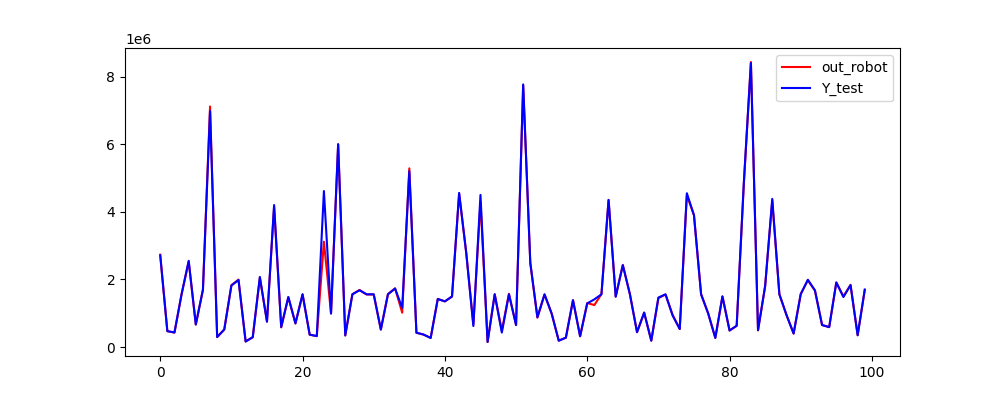

In [31]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(orginal_out_robot[:100],color='red')
plt.plot(orginal_y_test[:100],color='blue')
plt.legend(['out_robot','Y_test'])
plt.show()

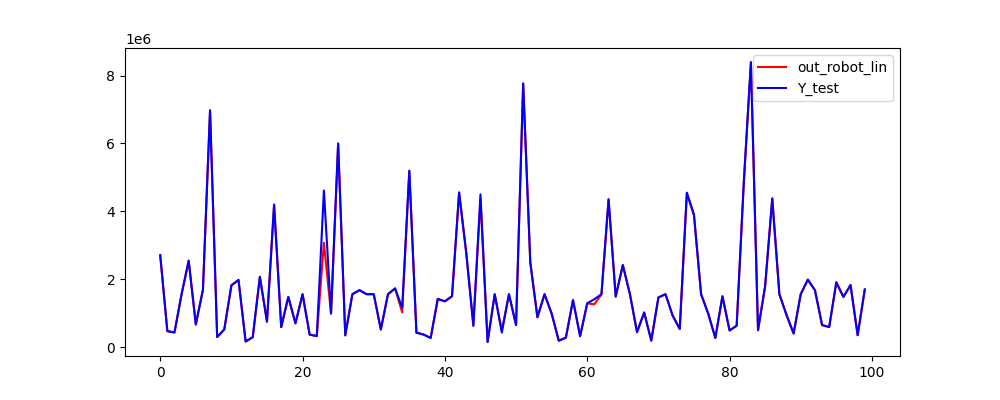

In [33]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(orginal_out_robot_lin[:100],color='red')
plt.plot(orginal_y_test_lin[:100],color='blue')
plt.legend(['out_robot_lin','Y_test'])
plt.show()

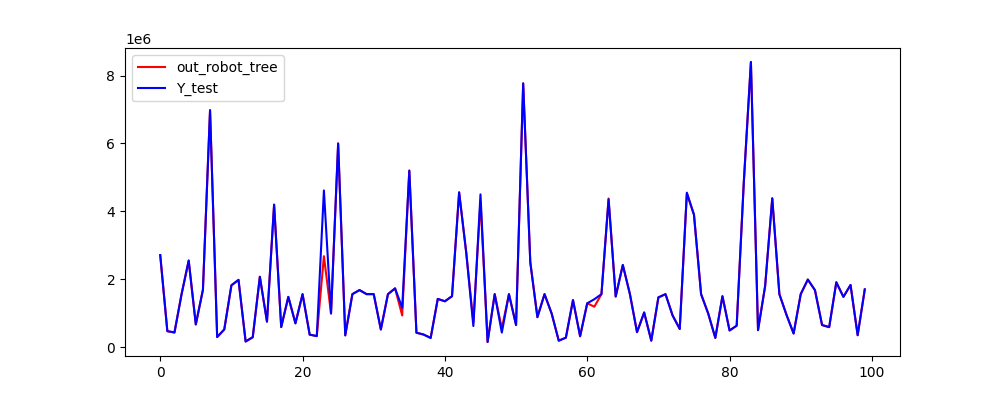

In [34]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(orginal_out_robot_tree[:100],color='red')
plt.plot(orginal_y_test_tree[:100],color='blue')
plt.legend(['out_robot_tree','Y_test'])
plt.show()